In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Đọc dữ liệu

In [ ]:
import pandas as pd

# Đường dẫn đến tập dữ liệu
file_path = '/content/drive/MyDrive/users_dataset/user_dataset.csv'

# Đọc tập dữ liệu vào DataFrame
try:
    df = pd.read_csv(file_path)

    # Hiển thị thông tin của DataFrame
    print("Thông tin về tập dữ liệu:")
    df.info()

    # Hiển thị 5 dòng đầu tiên
    print("\n5 dòng đầu tiên của tập dữ liệu:")
    display(df.head())

except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy tệp tại đường dẫn {file_path}")
except Exception as e:
    print(f"Đã xảy ra lỗi khi đọc tệp: {e}")

Thông tin về tập dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98913 entries, 0 to 98912
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   identifierHash       98913 non-null  int64  
 1   type                 98913 non-null  object 
 2   country              98913 non-null  object 
 3   language             98913 non-null  object 
 4   socialNbFollowers    98913 non-null  int64  
 5   socialNbFollows      98913 non-null  int64  
 6   socialProductsLiked  98913 non-null  int64  
 7   productsListed       98913 non-null  int64  
 8   productsSold         98913 non-null  int64  
 9   productsPassRate     98913 non-null  float64
 10  productsWished       98913 non-null  int64  
 11  productsBought       98913 non-null  int64  
 12  gender               98913 non-null  object 
 13  civilityGenderId     98913 non-null  int64  
 14  civilityTitle        98913 non-null  object 
 15  hasAnyApp 

,identifierHash,type,country,language,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsPassRate,...,civilityTitle,hasAnyApp,hasAndroidApp,hasIosApp,hasProfilePicture,daysSinceLastLogin,seniority,seniorityAsMonths,seniorityAsYears,countryCode
0,-1097895247965112460,user,Royaume-Uni,en,147,10,77,26,174,74.0,...,mr,True,False,True,True,11,3196,106.53,8.88,gb
1,2347567364561867620,user,Monaco,en,167,8,2,19,170,99.0,...,mrs,True,False,True,True,12,3204,106.80,8.90,mc
2,6870940546848049750,user,France,fr,137,13,60,33,163,94.0,...,mrs,True,False,True,False,11,3203,106.77,8.90,fr
3,-4640272621319568052,user,Etats-Unis,en,131,10,14,122,152,92.0,...,mrs,True,False,True,False,12,3198,106.60,8.88,us
4,-5175830994878542658,user,Etats-Unis,en,167,8,0,25,125,100.0,...,mrs,False,False,False,True,22,2854,95.13,7.93,us


In [ ]:
df.describe()

,identifierHash,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsPassRate,productsWished,productsBought,civilityGenderId,daysSinceLastLogin,seniority,seniorityAsMonths,seniorityAsYears
count,9.891300e+04,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000,98913.000000
mean,-6.692039e+15,3.432269,8.425677,4.420743,0.093304,0.121592,0.812303,1.562595,0.171929,1.773993,581.291236,3063.771870,102.125583,8.510424
std,5.330807e+18,3.882383,52.839572,181.030569,2.050144,2.126895,8.500205,25.192793,2.332266,0.428679,208.855888,168.298621,5.609735,0.467863
min,-9.223101e+18,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,2852.000000,95.070000,7.920000
25%,-4.622895e+18,3.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,572.000000,2857.000000,95.230000,7.940000
50%,-1.337989e+15,3.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,694.000000,3196.000000,106.530000,8.880000
75%,4.616388e+18,3.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,702.000000,3201.000000,106.700000,8.890000
max,9.223331e+18,744.000000,13764.000000,51671.000000,244.000000,174.000000,100.000000,2635.000000,405.000000,3.000000,709.000000,3205.000000,106.830000,8.900000


In [ ]:
nRowsRead = None

df1 = pd.read_csv(file_path, delimiter=',', nrows = nRowsRead)

df1.dataframeName = os.path.basename(file_path)

orig_df1 = df1.copy()
orig_df1.dataframeName = df1.dataframeName

nRow, nCol = df1.shape
print(f'Có {nRow} dòng (i.e. users) và {nCol} cột (i.e. possible features)')
print('\nCác cột: \n{}'.format(" - ".join(list(df1.columns))))

Có 98913 dòng (i.e. users) và 24 cột (i.e. possible features)

Các cột: 
identifierHash - type - country - language - socialNbFollowers - socialNbFollows - socialProductsLiked - productsListed - productsSold - productsPassRate - productsWished - productsBought - gender - civilityGenderId - civilityTitle - hasAnyApp - hasAndroidApp - hasIosApp - hasProfilePicture - daysSinceLastLogin - seniority - seniorityAsMonths - seniorityAsYears - countryCode


# Trực quan hóa dữ liệu sơ bộ

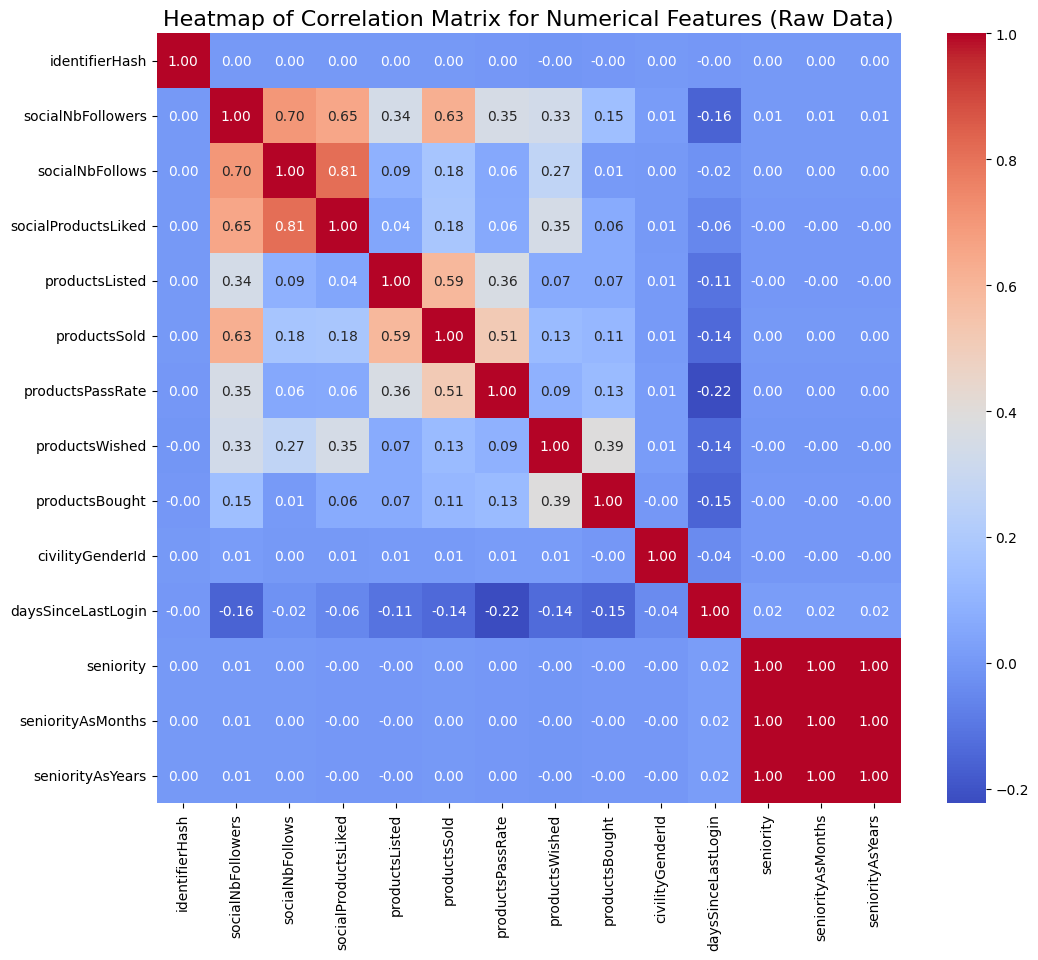

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Select only numerical columns from the original dataframe (df1)
numerical_df1 = df1.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix_raw = numerical_df1.corr()

# Create the heatmap
plt.figure(figsize=(12, 10)) # Adjust figure size for better readability if many columns
sns.heatmap(correlation_matrix_raw, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Correlation Matrix for Numerical Features (Raw Data)', fontsize=16)
plt.show()

In [ ]:
df_group_two = df1[['hasAnyApp','productsBought','productsSold']]
df_group_two = df_group_two.groupby(['hasAnyApp'],as_index=False).agg(['sum','mean'])

In [ ]:
print("Người dùng có app điện thoại đều mua và bán nhiều sản phẩm hơn so với người dùng không có app")
df_group_two

Người dùng có app điện thoại đều mua và bán nhiều sản phẩm hơn so với người dùng không có app


hasAnyApp productsBought           productsSold          
                       sum      mean          sum      mean
0     False           7957  0.109391         3233  0.044447
1      True           9049  0.345725         8794  0.335982

Text(0.5, 1.0, 'civilityTitle Bins')

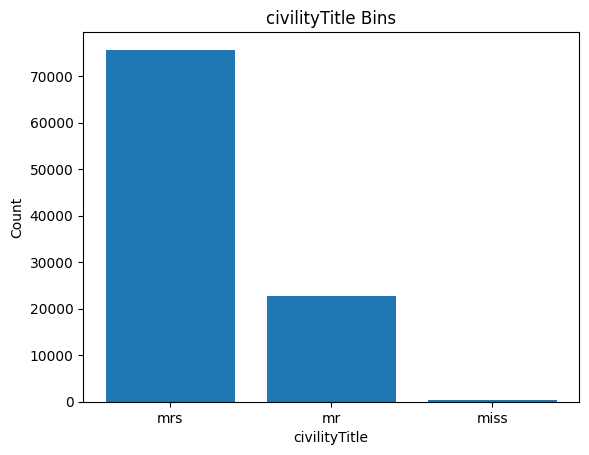

In [ ]:
%matplotlib inline
import matplotlib as plt
from matplotlib import pyplot
group_names=['mrs','mr','miss']
pyplot.bar(group_names, height=df1['civilityTitle'].value_counts())

# set x/y labels and plot title
plt.pyplot.xlabel("civilityTitle")
plt.pyplot.ylabel("Count")
plt.pyplot.title("civilityTitle Bins")

**PHỤ NỮ ĐÃ CÓ GIA ĐÌNH LÀ KHÁCH HÀNG NĂNG ĐỘNG NHẤT Ở SÀN GIAO DỊCH C2C (ONLINE)**

In [ ]:
df_group_one = df1[['civilityTitle','productsBought','productsSold']]
df_group_one = df_group_one.groupby(['civilityTitle'],as_index=False).agg(['sum',"mean"])
df_group_one

civilityTitle productsBought           productsSold          
                           sum      mean          sum      mean
0          miss            287  0.656751          574  1.313501
1            mr           4262  0.186995         2673  0.117278
2           mrs          12457  0.164592         8780  0.116009

**MẶC DÙ NHÓM PHỤ NỮ ĐỘC THÂN LÀ NHÓM CÓ SỐ LƯỢNG NHỎ NHẤT, SỨC MUA VÀ BÁN LẠI NẰM Ở MỨC CAO NHẤT (MEAN)**

Text(0.5, 1.0, 'hasAnyApp Bins')

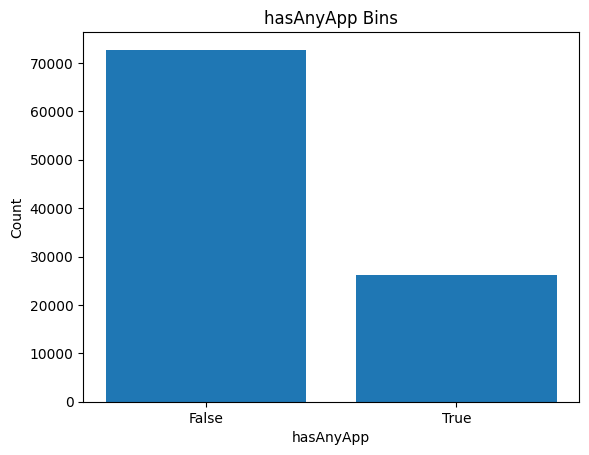

In [ ]:
%matplotlib inline
import matplotlib as plt
from matplotlib import pyplot
group_names=['False','True']
q=pyplot.bar(group_names, df1['hasAnyApp'].value_counts())

plt.pyplot.xlabel("hasAnyApp")
plt.pyplot.ylabel("Count")
plt.pyplot.title("hasAnyApp Bins")



**ĐA SỐ NGƯỜI DÙNG KHÔNG CÓ APP ĐIỆN THOẠI**

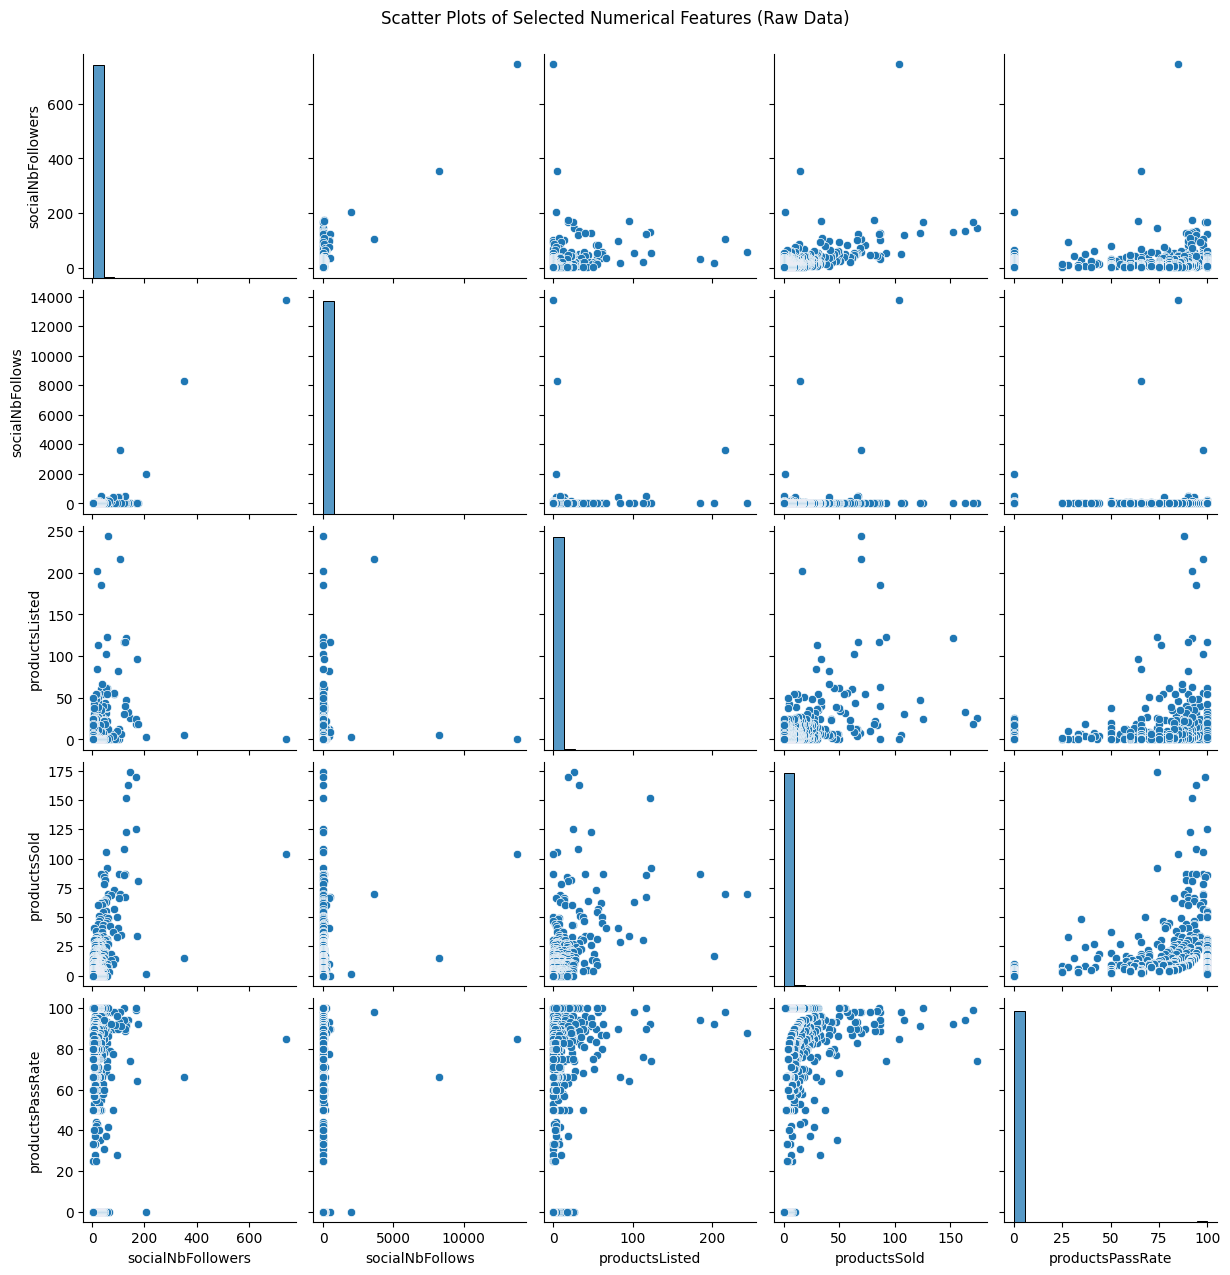

Value counts for selected categorical columns:
gender
F    76121
M    22792
Name: count, dtype: int64
hasAnyApp
False    72739
True     26174
Name: count, dtype: int64


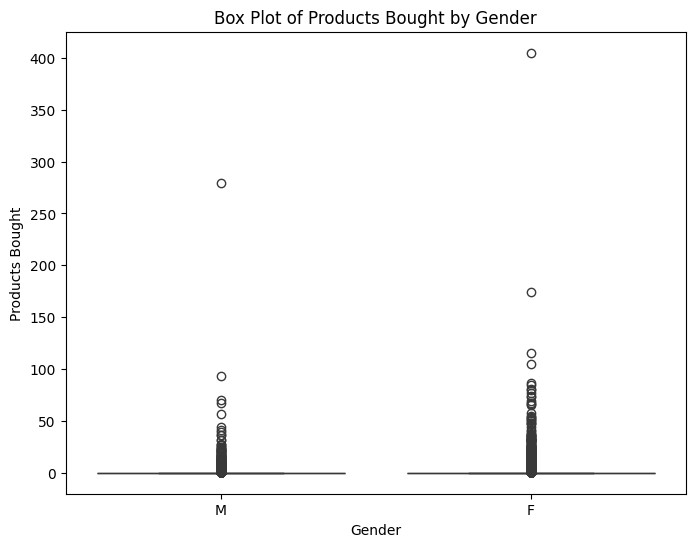

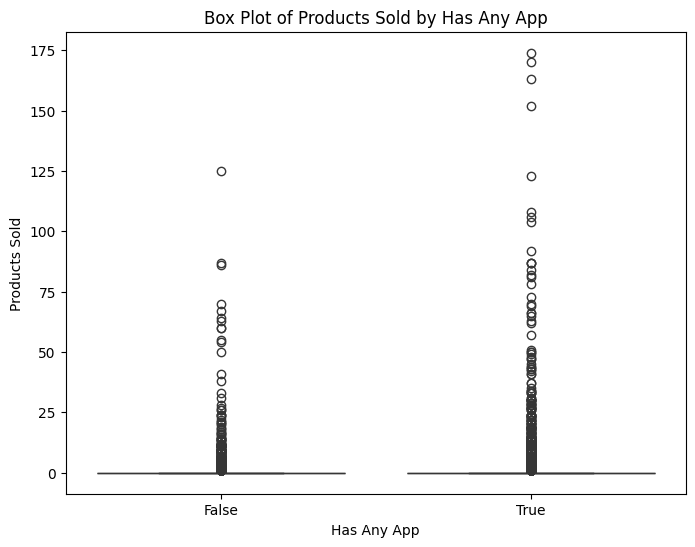

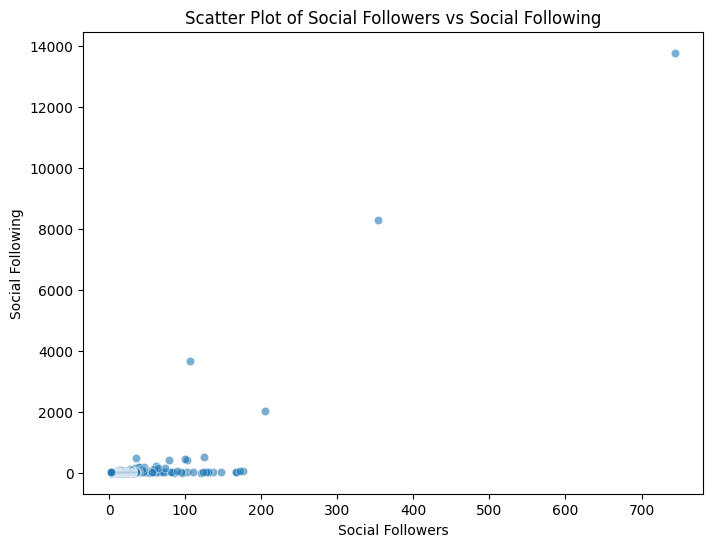

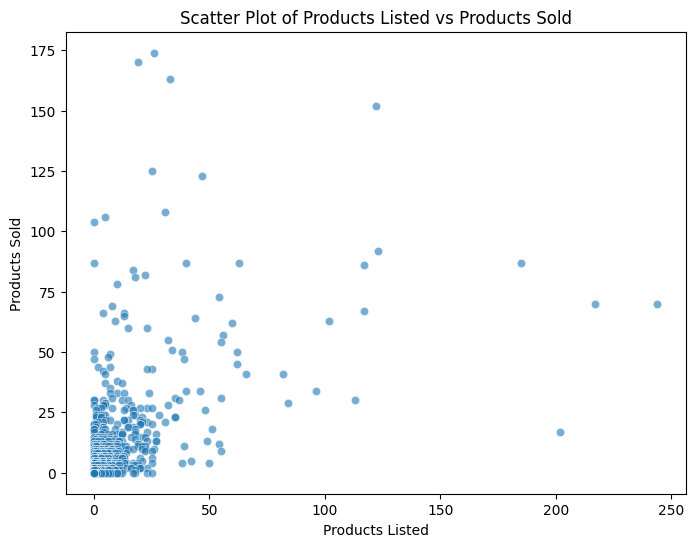

In [ ]:
# Initial Data Exploration with Scatter Plots and Box Plots

import matplotlib.pyplot as plt
import seaborn as sns

# Select a few numerical columns for scatter plots to see potential relationships
# and distributions. Including highly correlated numerical pairs.
numerical_cols_for_scatter = [
    'socialNbFollowers', 'socialNbFollows',
    'productsListed', 'productsSold',
    'productsPassRate' # Keeping this from previous analysis
]


sns.pairplot(df[numerical_cols_for_scatter])
plt.suptitle('Scatter Plots of Selected Numerical Features (Raw Data)', y=1.02)
plt.show()

# Select a few categorical columns for box plots to see the distribution of
# a numerical feature across different categories.
print("Value counts for selected categorical columns:")
print(df['gender'].value_counts())
print(df['hasAnyApp'].value_counts())

# Box plot for 'productsBought' vs 'gender'
plt.figure(figsize=(8, 6))
# Updated code to address FutureWarning
sns.boxplot(x='gender', y='productsBought', data=df, palette='viridis', hue='gender', legend=False)
plt.title('Box Plot of Products Bought by Gender')
plt.xlabel('Gender')
plt.ylabel('Products Bought')
plt.show()

# Box plot for 'productsSold' vs 'hasAnyApp'
plt.figure(figsize=(8, 6))
# Updated code to address FutureWarning
sns.boxplot(x='hasAnyApp', y='productsSold', data=df, palette='plasma', hue='hasAnyApp', legend=False)
plt.title('Box Plot of Products Sold by Has Any App')
plt.xlabel('Has Any App')
plt.ylabel('Products Sold')
plt.show()


# Scatter plot for socialNbFollowers vs socialNbFollows
plt.figure(figsize=(8, 6))
sns.scatterplot(x='socialNbFollowers', y='socialNbFollows', data=df, alpha=0.6)
plt.title('Scatter Plot of Social Followers vs Social Following')
plt.xlabel('Social Followers')
plt.ylabel('Social Following')
plt.show()

# Scatter plot for productsListed vs productsSold
plt.figure(figsize=(8, 6))
sns.scatterplot(x='productsListed', y='productsSold', data=df, alpha=0.6)
plt.title('Scatter Plot of Products Listed vs Products Sold')
plt.xlabel('Products Listed')
plt.ylabel('Products Sold')
plt.show()



Giới tính không phải yếu tố quyết định mạnh tới số lượng mua -> không ảnh hưởng tới hành vi người dùng

**Tập dữ liệu có nhiễu và lệch nhiều**


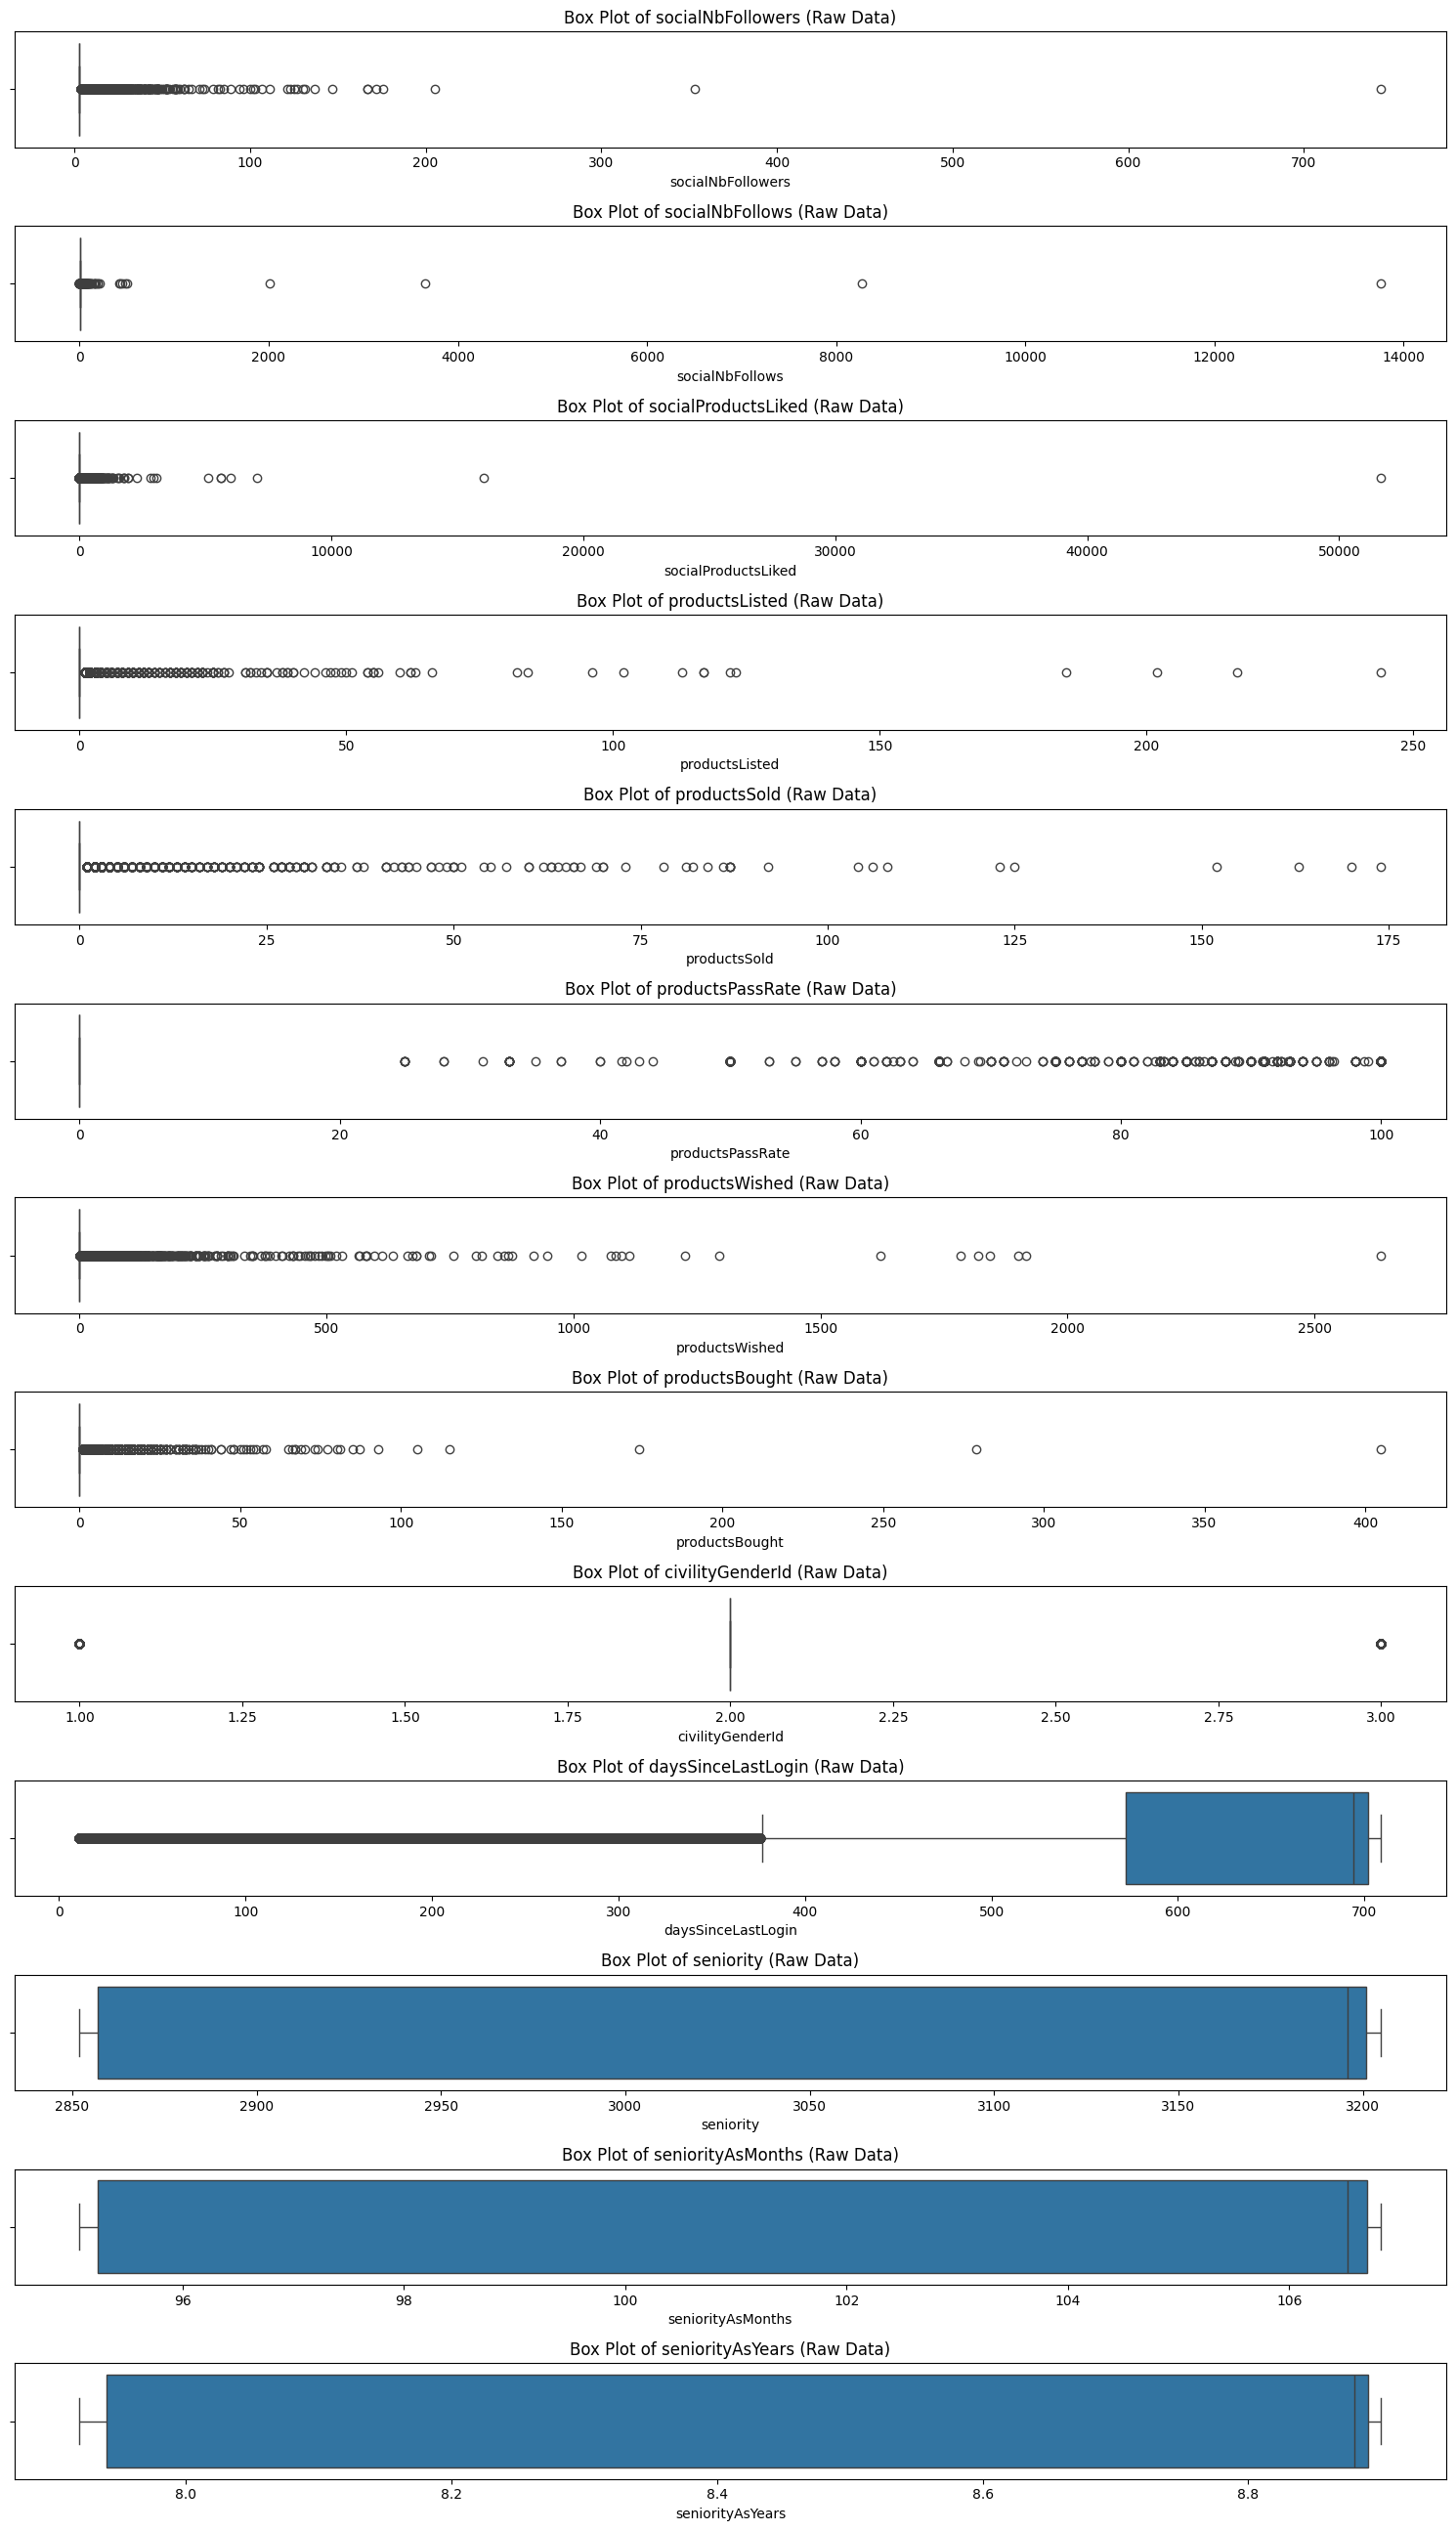

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Lấy danh sách các cột số từ df1
numerical_cols_raw = df1.select_dtypes(include=np.number).columns.tolist()

# Loại bỏ cột identifierHash nếu nó là số và không cần trực quan hóa box plot
if 'identifierHash' in numerical_cols_raw:
    numerical_cols_raw.remove('identifierHash')


# Tạo box plot cho từng thuộc tính số
plt.figure(figsize=(15, len(numerical_cols_raw) * 2)) # Điều chỉnh kích thước hình dựa trên số lượng cột
for i, col in enumerate(numerical_cols_raw):
    plt.subplot(len(numerical_cols_raw), 1, i + 1)
    sns.boxplot(x=df1[col]) # Thay đổi từ y sang x và sử dụng df1
    plt.title(f'Box Plot of {col} (Raw Data)')
    plt.xlabel(col) # Thay đổi từ ylabel sang xlabel

plt.tight_layout() # Điều chỉnh khoảng cách giữa các subplot
plt.show()

**DATA** **CLEANING**
# Kiểm tra giá trị thiếu và độ lệch của dữ liệu




In [ ]:
#kiểm tra giá trị thiếu
#print("Missing values per column:")
#print(df1.isna().sum())

# Kiểm tra độ lệch (skewness) chỉ cho các cột số
print("\nSkewness for numeric columns:")
numeric_cols = df1.select_dtypes(include=np.number)
numeric_cols.skew()


Skewness for numeric columns:


,0
identifierHash,0.001134
socialNbFollowers,88.816910
socialNbFollows,220.876679
socialProductsLiked,244.157743
productsListed,64.893219
productsSold,41.595633
productsPassRate,10.667299
productsWished,49.256959
productsBought,84.797360
civilityGenderId,-1.140820


In [ ]:
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

# Initialize the Isolation Forest model
iso_forest = IsolationForest(contamination='auto', random_state=42)

# columns to use for outlier detection.
cols_for_outlier_detection = [
    'socialNbFollowers', 'socialNbFollows', 'socialProductsLiked',
    'productsListed', 'productsSold', 'productsPassRate',
    'productsWished', 'productsBought', 'civilityGenderId',
    'daysSinceLastLogin',
    'seniority', 'seniorityAsMonths', 'seniorityAsYears'
]

# Ensure these columns exist in df1 and are numeric
numeric_cols = df1.select_dtypes(include=np.number).columns.tolist()
cols_for_outlier_detection = [col for col in cols_for_outlier_detection if col in numeric_cols]


# Apply Isolation Forest to the selected columns
df1_subset_for_outliers = df1[cols_for_outlier_detection].copy()


# Fit the Isolation Forest model and predict outliers (-1 for outliers, 1 for inliers)
outlier_predictions = iso_forest.fit_predict(df1_subset_for_outliers)

# Add outlier prediction back to the df1 dataframe
df1['outlier_iso_forest'] = outlier_predictions

# Filter out the outliers to create the cleaned dataframe for the next step
df1_cleaned_outliers = df1[df1['outlier_iso_forest'] == 1].copy()

print("Number of data points before outlier removal:", len(df1))
print("Number of outliers detected by Isolation Forest:", (outlier_predictions == -1).sum())
print("Number of data points after outlier removal:", len(df1_cleaned_outliers))

print("\nHead of the dataframe after outlier removal:")
display(df1_cleaned_outliers.head(5))

Number of data points before outlier removal: 98913
Number of outliers detected by Isolation Forest: 8711
Number of data points after outlier removal: 90202

Head of the dataframe after outlier removal:


,identifierHash,type,country,language,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsPassRate,...,hasAnyApp,hasAndroidApp,hasIosApp,hasProfilePicture,daysSinceLastLogin,seniority,seniorityAsMonths,seniorityAsYears,countryCode,outlier_iso_forest
1098,3506284051701885639,user,France,fr,3,8,0,0,2,0.0,...,False,False,False,True,466,2858,95.27,7.94,fr,1
1366,-269896976649086206,user,France,fr,6,8,1,0,1,0.0,...,True,True,False,True,584,3202,106.73,8.89,fr,1
1380,-911965964903082249,user,France,fr,6,8,0,0,1,0.0,...,True,False,True,False,346,3200,106.67,8.89,fr,1
1381,9174856632942776482,user,Allemagne,de,6,8,0,0,1,0.0,...,False,False,False,True,704,3200,106.67,8.89,de,1
1382,-5782470039826835733,user,France,fr,6,8,0,0,1,0.0,...,False,False,False,True,664,3200,106.67,8.89,fr,1


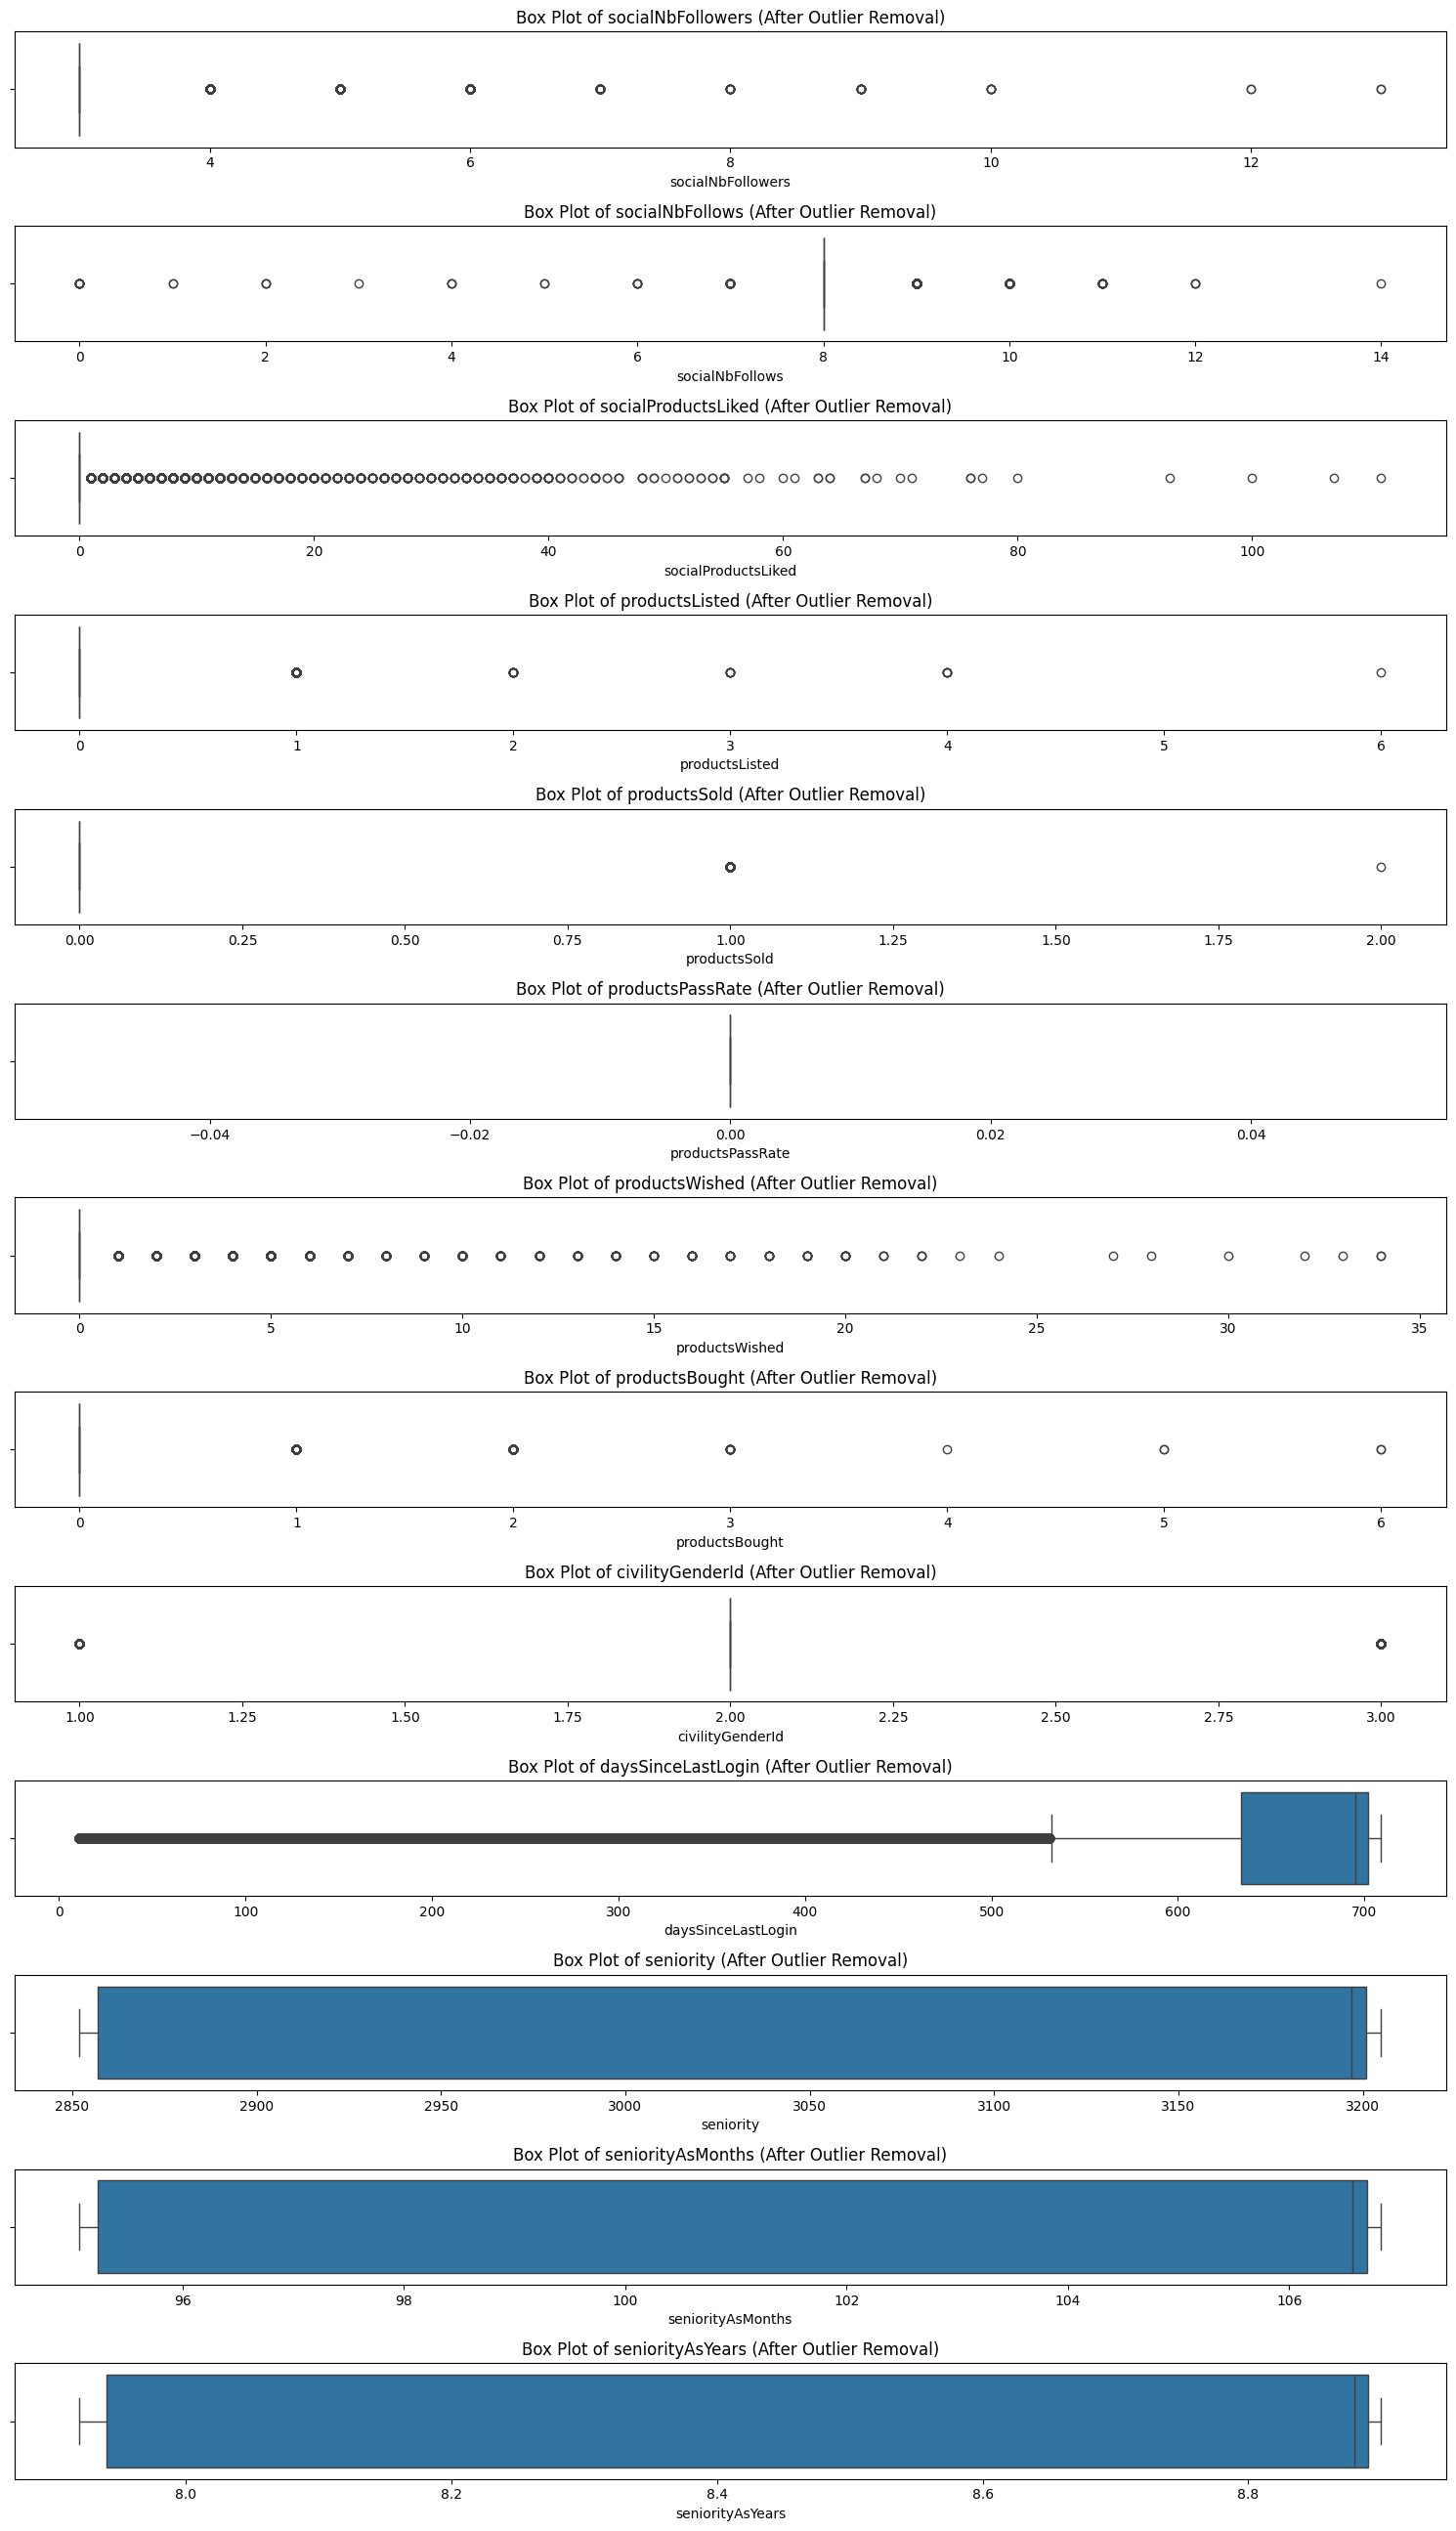

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Lấy danh sách các cột số từ df1_cleaned_outliers
numerical_cols_cleaned = df1_cleaned_outliers.select_dtypes(include=np.number).columns.tolist()

# Loại bỏ cột identifierHash và outlier_iso_forest nếu chúng là số và không cần trực quan hóa box plot
cols_to_remove = ['identifierHash', 'outlier_iso_forest']
numerical_cols_cleaned = [col for col in numerical_cols_cleaned if col not in cols_to_remove]

# Tạo box plot cho từng thuộc tính số
plt.figure(figsize=(15, len(numerical_cols_cleaned) * 2)) # Điều chỉnh kích thước hình dựa trên số lượng cột
for i, col in enumerate(numerical_cols_cleaned):
    plt.subplot(len(numerical_cols_cleaned), 1, i + 1)
    sns.boxplot(x=df1_cleaned_outliers[col])
    plt.title(f'Box Plot of {col} (After Outlier Removal)')
    plt.xlabel(col)

plt.tight_layout() # Điều chỉnh khoảng cách giữa các subplot
plt.show()

In [ ]:
from sklearn.preprocessing import QuantileTransformer
import numpy as np
import pandas as pd

cols_to_transform = [
    'socialNbFollowers', 'socialNbFollows', 'socialProductsLiked',
    'productsListed', 'productsSold', 'productsPassRate',
    'productsWished', 'productsBought', 'civilityGenderId',
    'daysSinceLastLogin'
]

cols_to_transform = [col for col in cols_to_transform if col in df1_cleaned_outliers.columns and np.issubdtype(df1_cleaned_outliers[col].dtype, np.number)]

df1_transformed = df1_cleaned_outliers.copy()

quantile_transformer = QuantileTransformer(output_distribution='normal',n_quantiles=1000, random_state=42)

df1_subset_to_transform = df1_transformed[cols_to_transform].copy()
for col in df1_subset_to_transform.columns:
    if np.issubdtype(df1_subset_to_transform[col].dtype, np.number):
        df1_subset_to_transform[col] = df1_subset_to_transform[col].replace([np.inf, -np.inf], np.nan)
        if df1_subset_to_transform[col].isnull().any():
            median_val = df1_subset_to_transform[col].median()
            df1_subset_to_transform[col].fillna(median_val, inplace=True)
            print(f"Filled NaN/Inf in {col} with median value before transformation.")


df1_transformed[cols_to_transform] = quantile_transformer.fit_transform(df1_subset_to_transform)


print("Head of the dataframe after Quantile Transformation:")
display(df1_transformed.head())

# Calculate and print skewness of the transformed numerical columns
print("\nSkewness for numeric columns after transformation:")
transformed_numeric_cols = df1_transformed[cols_to_transform].select_dtypes(include=np.number)
print(transformed_numeric_cols.skew())

Head of the dataframe after Quantile Transformation:


,identifierHash,type,country,language,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsPassRate,...,hasAnyApp,hasAndroidApp,hasIosApp,hasProfilePicture,daysSinceLastLogin,seniority,seniorityAsMonths,seniorityAsYears,countryCode,outlier_iso_forest
1098,3506284051701885639,user,France,fr,-5.199338,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,...,False,False,False,True,-1.041189,2858,95.27,7.94,fr,1
1366,-269896976649086206,user,France,fr,3.089935,-0.015055,1.411293,-5.199338,5.199338,-5.199338,...,True,True,False,True,-0.851675,3202,106.73,8.89,fr,1
1380,-911965964903082249,user,France,fr,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,...,True,False,True,False,-1.302166,3200,106.67,8.89,fr,1
1381,9174856632942776482,user,Allemagne,de,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,...,False,False,False,True,0.918498,3200,106.67,8.89,de,1
1382,-5782470039826835733,user,France,fr,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,...,False,False,False,True,-0.571638,3200,106.67,8.89,fr,1



Skewness for numeric columns after transformation:
socialNbFollowers       2.824036
socialNbFollows         7.017412
socialProductsLiked     2.568097
productsListed         20.116424
productsSold           23.606804
productsPassRate        0.000000
productsWished          4.177293
productsBought          7.161402
civilityGenderId       -1.286882
daysSinceLastLogin      1.575178
dtype: float64


# Loại bỏ các thuộc tính không cần thiết




In [ ]:
repeat_columns = []
# unused and repeated metadata are dropped
repeat_columns += ['identifierHash', 'type','country','gender','civilityTitle', 'seniority', 'seniorityAsMonths', 'seniorityAsYears', 'language', 'countryCode' ]
db1=df1_transformed.drop(repeat_columns,axis=1)
db1.head()

,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsPassRate,productsWished,productsBought,civilityGenderId,hasAnyApp,hasAndroidApp,hasIosApp,hasProfilePicture,daysSinceLastLogin,outlier_iso_forest
1098,-5.199338,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,-5.199338,0.275694,False,False,False,True,-1.041189,1
1366,3.089935,-0.015055,1.411293,-5.199338,5.199338,-5.199338,-5.199338,-5.199338,0.275694,True,True,False,True,-0.851675,1
1380,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,-5.199338,0.275694,True,False,True,False,-1.302166,1
1381,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,-5.199338,0.275694,False,False,False,True,0.918498,1
1382,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,-5.199338,0.275694,False,False,False,True,-0.571638,1


# Mã hóa dữ liệu

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

string_columns = ['hasAnyApp', 'hasAndroidApp', 'hasIosApp', 'hasProfilePicture']

db1_encoded = db1.copy()

encoded_data = onehot_encoder.fit_transform(db1_encoded[string_columns])

encoded_cols_names = onehot_encoder.get_feature_names_out(string_columns)
encoded_df = pd.DataFrame(encoded_data, columns=encoded_cols_names, index=db1_encoded.index)

db1_encoded = db1_encoded.drop(string_columns, axis=1)

db2 = pd.concat([db1_encoded, encoded_df], axis=1)

print("\nInformation about the dataframe after One-Hot Encoding:")
db2.info()


Information about the dataframe after One-Hot Encoding:
<class 'pandas.core.frame.DataFrame'>
Index: 90202 entries, 1098 to 98912
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   socialNbFollowers        90202 non-null  float64
 1   socialNbFollows          90202 non-null  float64
 2   socialProductsLiked      90202 non-null  float64
 3   productsListed           90202 non-null  float64
 4   productsSold             90202 non-null  float64
 5   productsPassRate         90202 non-null  float64
 6   productsWished           90202 non-null  float64
 7   productsBought           90202 non-null  float64
 8   civilityGenderId         90202 non-null  float64
 9   daysSinceLastLogin       90202 non-null  float64
 10  outlier_iso_forest       90202 non-null  int64  
 11  hasAnyApp_False          90202 non-null  float64
 12  hasAnyApp_True           90202 non-null  float64
 13  hasAndroidApp_False  

In [ ]:
print(db2.head(5))

      socialNbFollowers  socialNbFollows  socialProductsLiked  productsListed  \
1098          -5.199338        -0.015055            -5.199338       -5.199338   
1366           3.089935        -0.015055             1.411293       -5.199338   
1380           3.089935        -0.015055            -5.199338       -5.199338   
1381           3.089935        -0.015055            -5.199338       -5.199338   
1382           3.089935        -0.015055            -5.199338       -5.199338   

      productsSold  productsPassRate  productsWished  productsBought  \
1098      5.199338         -5.199338       -5.199338       -5.199338   
1366      5.199338         -5.199338       -5.199338       -5.199338   
1380      5.199338         -5.199338       -5.199338       -5.199338   
1381      5.199338         -5.199338       -5.199338       -5.199338   
1382      5.199338         -5.199338       -5.199338       -5.199338   

      civilityGenderId  daysSinceLastLogin  outlier_iso_forest  \
1098          

# Feature selection

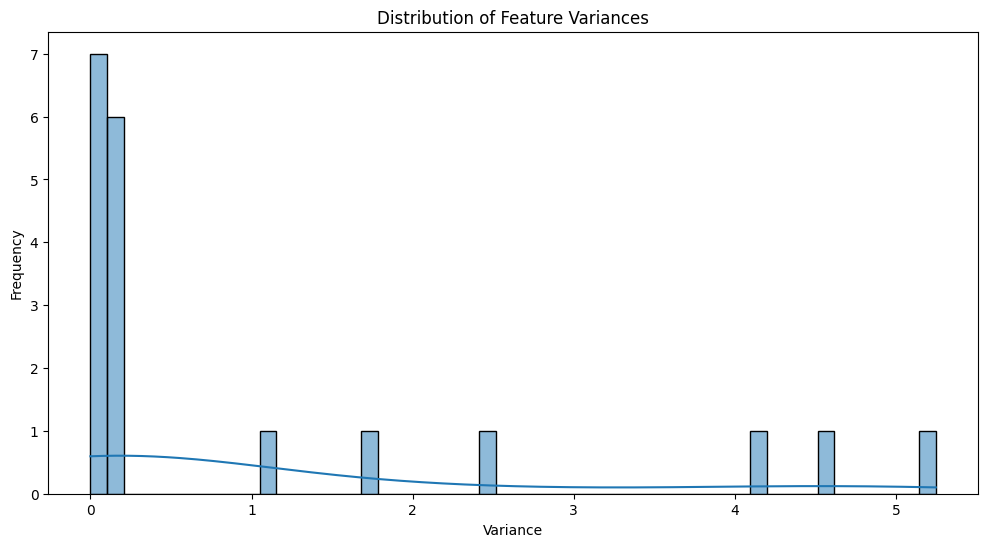

In [ ]:
# Tính toán phương sai của từng thuộc tính
variances = db2.var()

# Sắp xếp phương sai để dễ trực quan hóa
variances_sorted = variances.sort_values(ascending=False)

# Trực quan hóa phân phối phương sai
plt.figure(figsize=(12, 6))
sns.histplot(variances, bins=50, kde=True)
plt.title('Distribution of Feature Variances')
plt.xlabel('Variance')
plt.ylabel('Frequency')
plt.show()

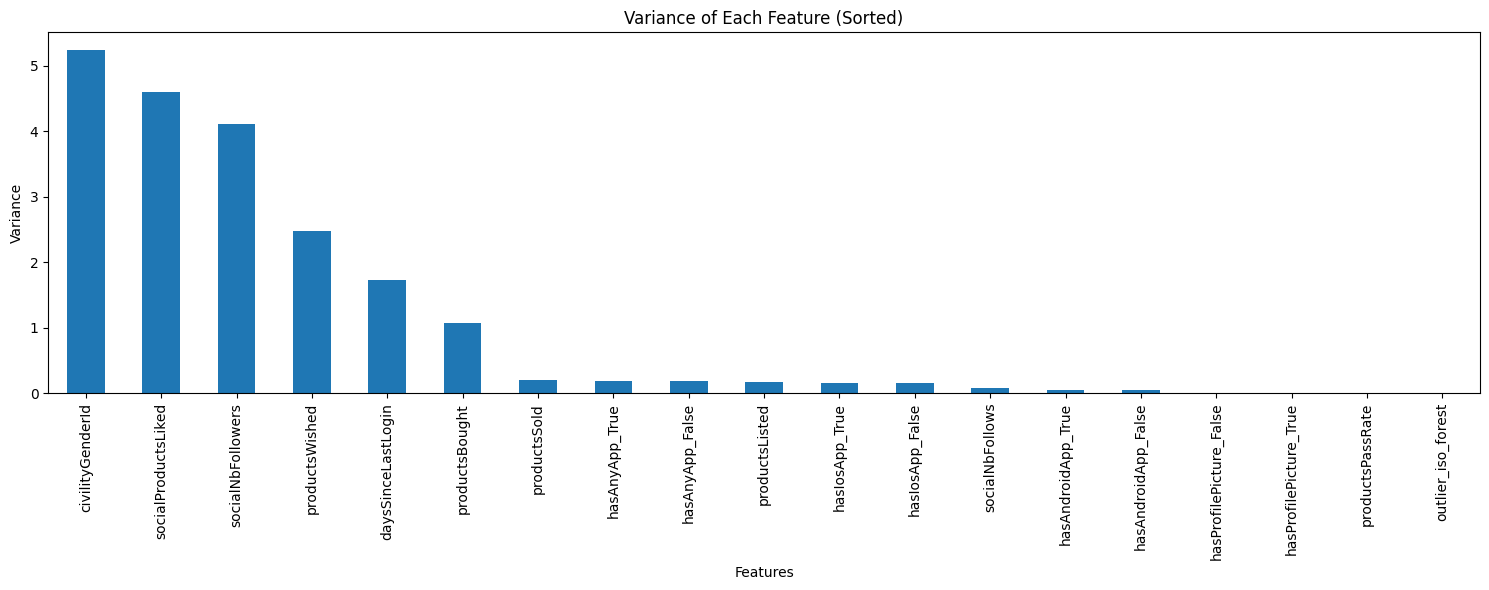


Phương sai của từng thuộc tính (sắp xếp giảm dần):


,0
civilityGenderId,5.248708e+00
socialProductsLiked,4.604819e+00
socialNbFollowers,4.109793e+00
productsWished,2.476263e+00
daysSinceLastLogin,1.720824e+00
productsBought,1.068855e+00
productsSold,1.926614e-01
hasAnyApp_True,1.805711e-01
hasAnyApp_False,1.805711e-01
productsListed,1.654060e-01


In [ ]:
# trực quan hóa phương sai của từng thuộc tính
plt.figure(figsize=(15, 6))
variances_sorted.plot(kind='bar')
plt.title('Variance of Each Feature (Sorted)')
plt.xlabel('Features')
plt.ylabel('Variance')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("\nPhương sai của từng thuộc tính (sắp xếp giảm dần):")
display(variances_sorted)

In [ ]:
from sklearn.feature_selection import VarianceThreshold

# Chọn ngưỡng phương sai dựa trên phân tích trước đó
threshold = 1e-2

# Áp dụng Variance Threshold
selector = VarianceThreshold(threshold=threshold)
db3 = selector.fit_transform(db2)

# Chuyển kết quả về DataFrame để dễ làm việc
# Lấy tên các cột được giữ lại
selected_columns = db2.columns[selector.get_support()]
db3 = pd.DataFrame(db3, columns=selected_columns)

print(f"Số lượng thuộc tính trước Variance Threshold: {db2.shape[1]}")
print(f"Số lượng thuộc tính sau Variance Threshold: {db3.shape[1]}")

display(db3.head())

Số lượng thuộc tính trước Variance Threshold: 19
Số lượng thuộc tính sau Variance Threshold: 15


,socialNbFollowers,socialNbFollows,socialProductsLiked,productsListed,productsSold,productsWished,productsBought,civilityGenderId,daysSinceLastLogin,hasAnyApp_False,hasAnyApp_True,hasAndroidApp_False,hasAndroidApp_True,hasIosApp_False,hasIosApp_True
0,-5.199338,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,0.275694,-1.041189,1.0,0.0,1.0,0.0,1.0,0.0
1,3.089935,-0.015055,1.411293,-5.199338,5.199338,-5.199338,-5.199338,0.275694,-0.851675,0.0,1.0,0.0,1.0,1.0,0.0
2,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,0.275694,-1.302166,0.0,1.0,1.0,0.0,0.0,1.0
3,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,0.275694,0.918498,1.0,0.0,1.0,0.0,1.0,0.0
4,3.089935,-0.015055,-5.199338,-5.199338,5.199338,-5.199338,-5.199338,0.275694,-0.571638,1.0,0.0,1.0,0.0,1.0,0.0


# Feature extraction

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Chuẩn hóa dữ liệu bằng StandardScaler
scaler = StandardScaler()
db3_scaled = scaler.fit_transform(db3)

# Áp dụng PCA
# Khởi tạo PCA với n_components = 10 để giảm chiều
pca = PCA(n_components=10) # Cập nhật n_components
db4 = pca.fit_transform(db3_scaled)

# Chuyển kết quả về DataFrame
# Cập nhật tên cột để phản ánh thành phần chính
db4 = pd.DataFrame(db4, columns=[f'PC{i+1}' for i in range(db4.shape[1])])


print(f"Số lượng thuộc tính sau PCA: {db4.shape[1]}")
display(db4.head())


print("\nTỷ lệ phương sai được giải thích bởi mỗi thành phần chính:")
display(pd.DataFrame(pca.explained_variance_ratio_, index=[f'PC{i+1}' for i in range(pca.n_components_)], columns=['Explained Variance Ratio']))


print(f"\nTổng phương sai được giải thích bởi 10 thành phần chính: {pca.explained_variance_ratio_.sum():.4f}")

Số lượng thuộc tính sau PCA: 10


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,0.783423,-0.141955,1.503567,9.835676,-8.963434,-12.783978,-11.462437,-7.012594,-4.171787,4.493334
1,-3.572532,-6.523316,3.586907,12.007375,-8.469026,-13.138857,-10.897486,-6.026499,-1.276957,3.870188
2,-3.945973,1.010815,1.578216,12.695116,-8.123671,-13.256239,-10.699326,-6.015709,-1.868877,3.609643
3,0.906277,-0.152706,1.632947,12.574166,-8.111009,-13.422447,-10.457936,-6.021498,-1.309882,4.540435
4,0.770782,-0.132697,2.105485,12.571433,-8.142744,-13.194204,-10.758387,-6.280293,-1.612800,3.732954



Tỷ lệ phương sai được giải thích bởi mỗi thành phần chính:


,Explained Variance Ratio
PC1,0.264445
PC2,0.142918
PC3,0.096713
PC4,0.073359
PC5,0.067742
PC6,0.066390
PC7,0.065471
PC8,0.062951
PC9,0.057665
PC10,0.055500



Tổng phương sai được giải thích bởi 10 thành phần chính: 0.9532


# Tìm k (số cụm) lý tưởng

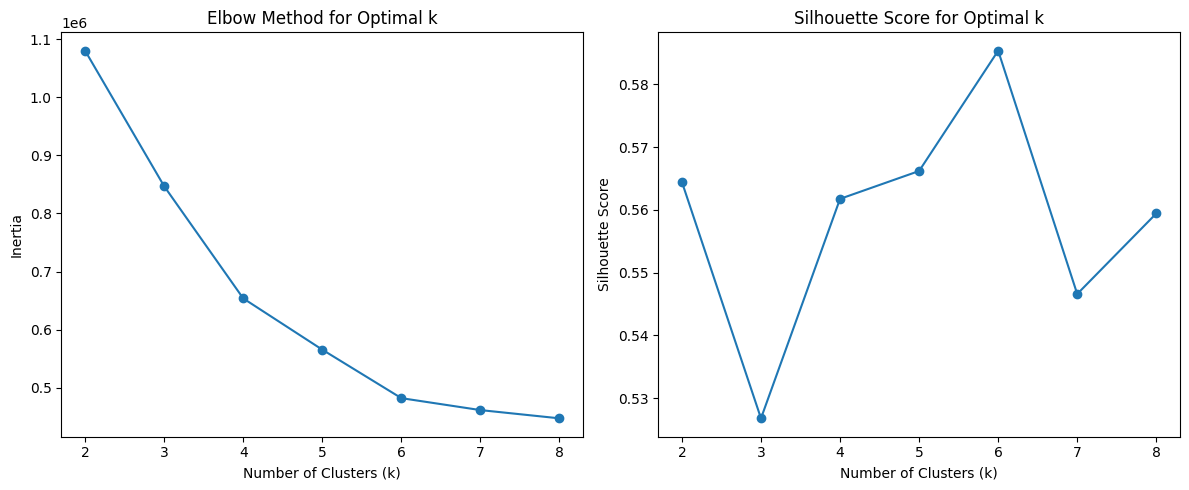

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np


k_range = range(2, 9)

# Danh sách để lưu trữ Inertia và Silhouette Score cho mỗi giá trị k
inertia_values = []
silhouette_scores = []

for k in k_range:
    # n_init='auto' là giá trị mặc định mới trong scikit-learn >= 1.2
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(db4)

    inertia_values.append(kmeans.inertia_)

    # Tính toán và lưu Silhouette Score (đk: k > 1)
    if k > 1:
        cluster_labels = kmeans.labels_
        silhouette_avg = silhouette_score(db4, cluster_labels)
        silhouette_scores.append(silhouette_avg)
    else: #k=2 -> ko xảy ra
         pass


# Vẽ biểu đồ Elbow Method
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1) # Tạo subplot 1 (1 hàng, 2 cột, vị trí 1)
plt.plot(k_range, inertia_values, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_range) # Đảm bảo hiển thị tất cả các giá trị k trong phạm vi

# Vẽ biểu đồ Silhouette Score
plt.subplot(1, 2, 2) # Tạo subplot 2 (1 hàng, 2 cột, vị trí 2)
# Lấy các giá trị k tương ứng với silhouette scores (từ k=2 trở đi)
# k_for_silhouette = list(k_range)[1:] # Dòng này gây lỗi
plt.plot(k_range, silhouette_scores, marker='o') # Sử dụng k_range cho trục x
plt.title('Silhouette Score for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range) # Đảm bảo hiển thị tất cả các giá trị k đã tính silhouette

plt.tight_layout() # Tự động điều chỉnh khoảng cách giữa các subplot
plt.show()

# Áp dụng K-Means Clustering với số lượng cụm tối ưu

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Số lượng cụm tối ưu đã chọn
optimal_k = 4

# Áp dụng K-Means Clustering với k=5 trên dữ liệu sau PCA (db5)
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
kmeans_final.fit(db4)

# Lấy nhãn cụm cho từng điểm dữ liệu
final_cluster_labels = kmeans_final.labels_

# Thêm nhãn cụm vào DataFrame db5 để dễ dàng phân tích sau này (tùy chọn)
db4_clustered = db4.copy()
db4_clustered['Cluster'] = final_cluster_labels

print(f"Đã áp dụng K-Means với k={optimal_k}. Nhãn cụm đã được tạo.")
display(db4_clustered.head())

Đã áp dụng K-Means với k=4. Nhãn cụm đã được tạo.


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Cluster
0,0.783423,-0.141955,1.503567,9.835676,-8.963434,-12.783978,-11.462437,-7.012594,-4.171787,4.493334,0
1,-3.572532,-6.523316,3.586907,12.007375,-8.469026,-13.138857,-10.897486,-6.026499,-1.276957,3.870188,3
2,-3.945973,1.010815,1.578216,12.695116,-8.123671,-13.256239,-10.699326,-6.015709,-1.868877,3.609643,1
3,0.906277,-0.152706,1.632947,12.574166,-8.111009,-13.422447,-10.457936,-6.021498,-1.309882,4.540435,0
4,0.770782,-0.132697,2.105485,12.571433,-8.142744,-13.194204,-10.758387,-6.280293,-1.612800,3.732954,0


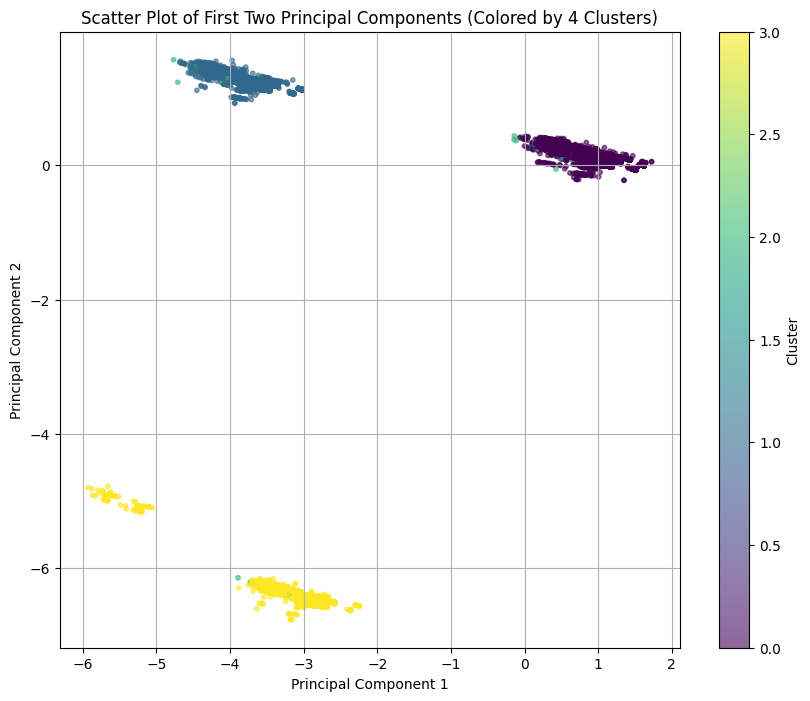

In [ ]:
# Vẽ biểu đồ scatter của 2 thành phần chính đầu tiên, tô màu theo cụm
plt.figure(figsize=(10, 8))

# Chọn 2 thành phần chính đầu tiên từ db4
pca_components = db4.iloc[:, :2]

# Vẽ scatter plot, sử dụng nhãn cụm final_cluster_labels để tô màu
scatter = plt.scatter(pca_components.iloc[:, 0], pca_components.iloc[:, 1],
                      c=final_cluster_labels, cmap='viridis', s=10, alpha=0.6)

plt.title(f'Scatter Plot of First Two Principal Components (Colored by {optimal_k} Clusters)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(scatter, label='Cluster') # Thêm thanh màu chú thích
plt.grid(True)
plt.show()


Đã áp dụng K-Means với k=6. Nhãn cụm đã được tạo.


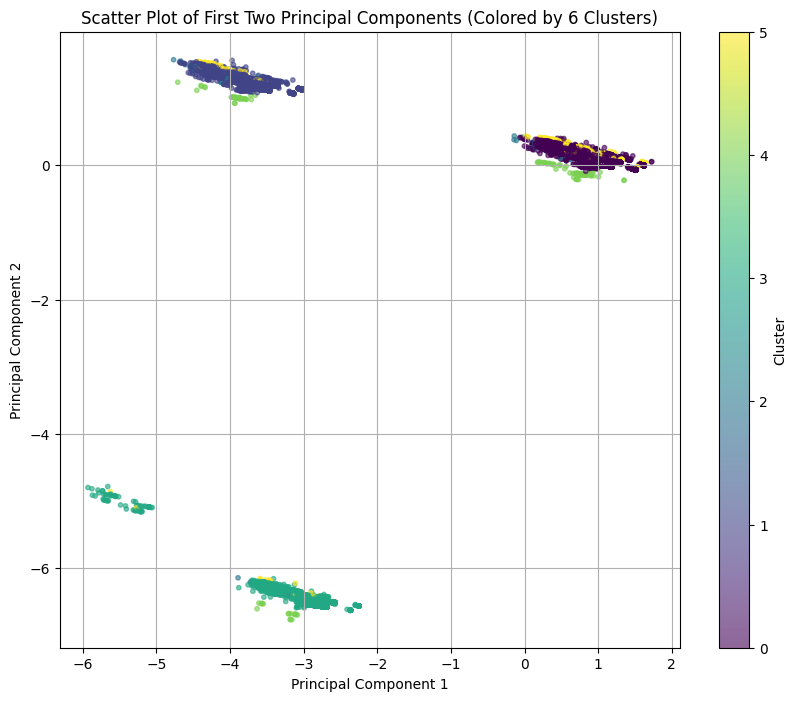

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Số lượng cụm đã chọn
selected_k = 6

# Áp dụng K-Means Clustering với k=6 trên dữ liệu sau PCA (db4)
kmeans_k6 = KMeans(n_clusters=selected_k, random_state=42, n_init='auto')
kmeans_k6.fit(db4)

# Lấy nhãn cụm cho từng điểm dữ liệu
cluster_labels_k6 = kmeans_k6.labels_

print(f"Đã áp dụng K-Means với k={selected_k}. Nhãn cụm đã được tạo.")

# Vẽ biểu đồ scatter của 2 thành phần chính đầu tiên, tô màu theo cụm
plt.figure(figsize=(10, 8))

# Chọn 2 thành phần chính đầu tiên từ db4
pca_components = db4.iloc[:, :2]

# Vẽ scatter plot, sử dụng nhãn cụm cluster_labels_k6 để tô màu
scatter = plt.scatter(pca_components.iloc[:, 0], pca_components.iloc[:, 1],
                      c=cluster_labels_k6, cmap='viridis', s=10, alpha=0.6)

plt.title(f'Scatter Plot of First Two Principal Components (Colored by {selected_k} Clusters)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(scatter, label='Cluster') # Thêm thanh màu chú thích
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
import pandas as pd

k_range = range(2, 10)
davies_bouldin_values = {}
calinski_harabasz_values = {}

print("Calculating Davies-Bouldin and Calinski-Harabasz Scores for k from 2 to 9:")

for k in k_range:
    # Khởi tạo và huấn luyện mô hình K-Means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(db4)

    # Tính toán chỉ số Davies-Bouldin
    db_score = davies_bouldin_score(db4, kmeans.labels_)
    davies_bouldin_values[k] = db_score
    print(f"k={k}: Davies-Bouldin Index = {db_score:.4f}")

    # Tính toán chỉ số Calinski-Harabasz
    ch_score = calinski_harabasz_score(db4, kmeans.labels_)
    calinski_harabasz_values[k] = ch_score
    print(f"k={k}: Calinski-Harabasz Index = {ch_score:.4f}")

print("\nSummary of Evaluation Scores:")
# Chuyển kết quả sang Series để dễ hiển thị
davies_bouldin_series = pd.Series(davies_bouldin_values, name="Davies-Bouldin Index")
calinski_harabasz_series = pd.Series(calinski_harabasz_values, name="Calinski-Harabasz Index")
silhouette_series = pd.Series(silhouette_scores, name="Silhouette Score") # Lấy kết quả từ lần chạy trước

# Kết hợp các chỉ số vào một DataFrame để dễ so sánh
evaluation_summary = pd.DataFrame({
    'Silhouette Score': silhouette_series,
    'Davies-Bouldin Index': davies_bouldin_series,
    'Calinski-Harabasz Index': calinski_harabasz_series
})

# Sắp xếp theo Silhouette Score giảm dần (hoặc theo chỉ số khác tùy ý)
display(evaluation_summary.sort_values(by='Silhouette Score', ascending=False))

Calculating Davies-Bouldin and Calinski-Harabasz Scores for k from 2 to 9:
k=2: Davies-Bouldin Index = 0.6783
k=2: Calinski-Harabasz Index = 17497.8439
k=3: Davies-Bouldin Index = 0.8936
k=3: Calinski-Harabasz Index = 23585.7716
k=4: Davies-Bouldin Index = 0.6360
k=4: Calinski-Harabasz Index = 29248.5869
k=5: Davies-Bouldin Index = 0.5461
k=5: Calinski-Harabasz Index = 28879.6885
k=6: Davies-Bouldin Index = 0.5584
k=6: Calinski-Harabasz Index = 30225.9054
k=7: Davies-Bouldin Index = 0.7313
k=7: Calinski-Harabasz Index = 26980.0010
k=8: Davies-Bouldin Index = 0.9225
k=8: Calinski-Harabasz Index = 24268.9192
k=9: Davies-Bouldin Index = 0.8471
k=9: Calinski-Harabasz Index = 29163.5500

Summary of Evaluation Scores:


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
4,0.585369,0.636038,29248.586888
3,0.566194,0.893623,23585.771565
0,0.564433,NaN,NaN
2,0.561754,0.678280,17497.843896
6,0.559425,0.558374,30225.905387
5,0.546589,0.546094,28879.688532
1,0.526767,NaN,NaN
7,NaN,0.731251,26980.001027
8,NaN,0.922511,24268.919233
9,NaN,0.847119,29163.550029


# Kiểm tra Overfitting trong mô hình phân cụm

In [ ]:
# Hiển thị lại explained variance của 2 thành phần chính đầu tiên
print("Tỷ lệ phương sai được giải thích bởi 2 thành phần chính đầu tiên:")
display(pd.DataFrame(pca.explained_variance_ratio_[:2], index=[f'PC{i+1}' for i in range(2)], columns=['Explained Variance Ratio']))

print(f"\nTổng phương sai được giải thích bởi 2 thành phần chính đầu tiên: {pca.explained_variance_ratio_[:2].sum():.4f}")

Tỷ lệ phương sai được giải thích bởi 2 thành phần chính đầu tiên:


,Explained Variance Ratio
PC1,0.264445
PC2,0.142918



Tổng phương sai được giải thích bởi 2 thành phần chính đầu tiên: 0.4074


Silhouette Scores on the test set for k in range 2 to 9:
k=2: 0.5641
k=3: 0.5638
k=4: 0.5560
k=5: 0.5527
k=6: 0.5570
k=7: 0.4347
k=8: 0.4317
k=9: 0.5221


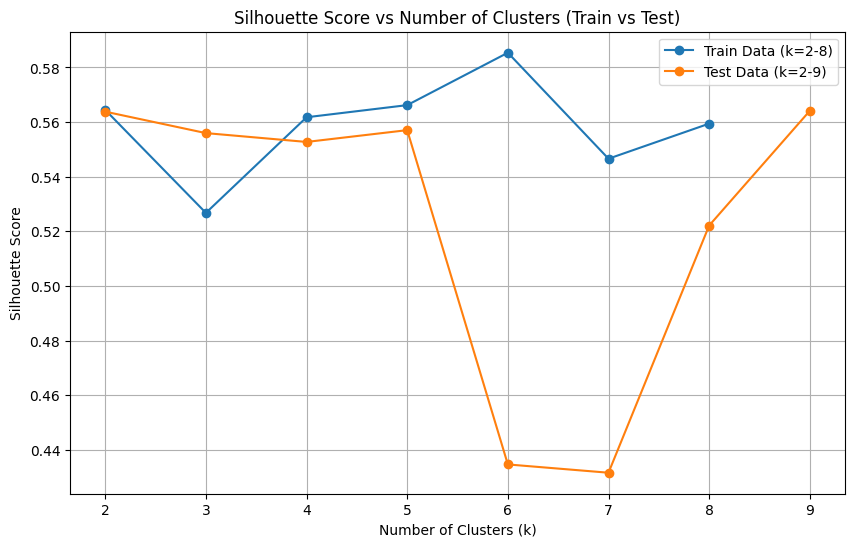

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# Chia dữ liệu (db4) thành tập huấn luyện và tập kiểm tra
X_train, X_test = train_test_split(db4, test_size=0.2, random_state=42)

silhouette_scores_test = []

# Lặp qua k_range (từ 2 đến 9)
k_range = range(2, 10) # Ensure k_range is correctly defined

for k in k_range:
    # Huấn luyện mô hình K-Means trên tập huấn luyện
    kmeans_train = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans_train.fit(X_train)

    # Dự đoán nhãn cụm trên tập kiểm tra
    cluster_labels_test = kmeans_train.predict(X_test)

    # Tính Silhouette Score trên tập kiểm tra và lưu kết quả
    if k > 1:
        silhouette_avg_test = silhouette_score(X_test, cluster_labels_test)
        silhouette_scores_test.append(silhouette_avg_test)
    else: # k=1 is not possible for silhouette_score
        pass


print("Silhouette Scores on the test set for k in range 2 to 9:")
for i, k in enumerate(k_range):
  if k > 1:
    print(f"k={k}: {silhouette_scores_test[i-1]:.4f}")


# Vẽ biểu đồ Silhouette Score cho tập huấn luyện và tập kiểm tra
plt.figure(figsize=(10, 6))

# Biểu đồ cho tập huấn luyện (sử dụng biến silhouette_scores từ bước trước đó)
# Check if silhouette_scores from the previous step is available and has the correct length
if 'silhouette_scores' in locals() and len(silhouette_scores) == len(list(range(2,9))):
    plt.plot(list(range(2,9)), silhouette_scores, marker='o', label='Train Data (k=2-8)') # Adjusted x-axis for train data
elif 'silhouette_scores' in locals() and len(silhouette_scores) == len(list(range(2,10))):
     plt.plot(list(range(2,10)), silhouette_scores, marker='o', label='Train Data (k=2-9)')
else:
    print("Warning: 'silhouette_scores' from previous step not found or has unexpected length. Plotting only test data scores.")
    # If silhouette_scores is not available or incorrect, plot only test data
    plt.plot(k_range, silhouette_scores_test, marker='o', label='Test Data (k=2-9)')


# Biểu đồ cho tập kiểm tra
# Adjusted the x-axis for test data to match the k_range used for calculation
plt.plot(k_range, silhouette_scores_test, marker='o', label='Test Data (k=2-9)')


plt.title('Silhouette Score vs Number of Clusters (Train vs Test)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range) # Ensure all k values in range are shown
plt.legend()
plt.grid(True)
plt.show()

Thực hiện 50 lần chia train/test để phân tích khoảng cách Silhouette cho k=[4, 5]...

--- Phân tích Khoảng cách Silhouette Train-Test (Trung bình và CI 95% trên 50 lần chia) ---
k | Trung bình Khoảng cách | CI 95% cho Khoảng cách
---|---------------------|----------------
4 | 0.0002           | (-0.0058, 0.0095)
5 | 0.0001           | (-0.0064, 0.0066)


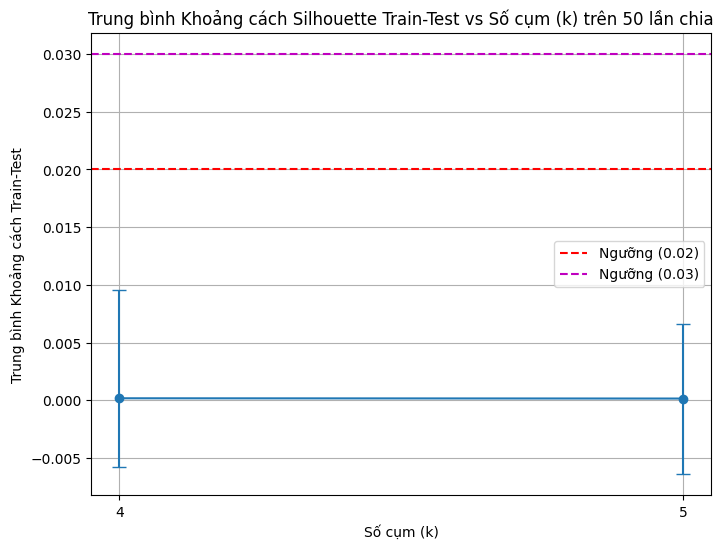

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kiểm tra sự tồn tại của db3
if 'db3' not in locals():
    print("Lỗi: Không tìm thấy dataframe db3. Vui lòng chạy các bước tiền xử lý trước đó.")
else:
    n_splits = 50  # Số lần chia tập train/test
    k_values_to_check = [4, 5] # Các giá trị k cần kiểm tra

    # Lưu trữ khoảng cách Silhouette (Train - Test) qua các lần chia cho k=4 và k=5
    silhouette_gaps_across_splits = {k: [] for k in k_values_to_check}

    print(f"Thực hiện {n_splits} lần chia train/test để phân tích khoảng cách Silhouette cho k={k_values_to_check}...")

    for i in range(n_splits):
        # Chia dữ liệu thô trước khi scale và PCA
        X_train_raw, X_test_raw = train_test_split(db3, test_size=0.2, random_state=i)

        # Scale và PCA chỉ fit trên tập train
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_raw)
        X_test_scaled = scaler.transform(X_test_raw)

        pca = PCA(n_components=10) # Sử dụng cùng số thành phần như trước
        X_train_pca = pca.fit_transform(X_train_scaled)
        X_test_pca = pca.transform(X_test_scaled)


        for k in k_values_to_check:
            # Huấn luyện KMeans trên tập train (sau PCA)
            kmeans_train = KMeans(n_clusters=k, random_state=42, n_init='auto')
            kmeans_train.fit(X_train_pca)

            # Tính Silhouette Score trên tập train
            silhouette_train = silhouette_score(X_train_pca, kmeans_train.labels_)

            # Predict clusters on the test set (using the model trained on train)
            cluster_labels_test = kmeans_train.predict(X_test_pca)

            # Tính Silhouette Score trên tập test
            silhouette_test = silhouette_score(X_test_pca, cluster_labels_test)

            # Tính khoảng cách train-test và lưu
            silhouette_gap = silhouette_train - silhouette_test
            silhouette_gaps_across_splits[k].append(silhouette_gap)


    # Tính trung bình và 95% confidence interval cho khoảng cách Silhouette
    mean_silhouette_gap = {k: np.mean(gaps) for k, gaps in silhouette_gaps_across_splits.items() if gaps}
    ci_silhouette_gap = {k: (np.percentile(gaps, 2.5), np.percentile(gaps, 97.5)) for k, gaps in silhouette_gaps_across_splits.items() if gaps}


    print("\n--- Phân tích Khoảng cách Silhouette Train-Test (Trung bình và CI 95% trên 50 lần chia) ---")
    print("k | Trung bình Khoảng cách | CI 95% cho Khoảng cách")
    print("---|---------------------|----------------")
    for k in k_values_to_check:
        gap_mean = mean_silhouette_gap.get(k, np.nan)
        gap_ci = ci_silhouette_gap.get(k, (np.nan, np.nan))
        print(f"{k} | {gap_mean:.4f}           | ({gap_ci[0]:.4f}, {gap_ci[1]:.4f})")

    # Trực quan hóa Trung bình Khoảng cách Train-Test cho k=4 và k=5
    plt.figure(figsize=(8, 6))
    k_plot_gap = list(mean_silhouette_gap.keys())
    mean_gaps = list(mean_silhouette_gap.values())
    ci_gaps = [ci_silhouette_gap[k] for k in k_plot_gap]

    lower_ci = [gap_mean - ci[0] for gap_mean, ci in zip(mean_gaps, ci_gaps)]
    upper_ci = [ci[1] - gap_mean for gap_mean, ci in zip(mean_gaps, ci_gaps)]


    plt.errorbar(k_plot_gap, mean_gaps,
                 yerr=[lower_ci, upper_ci],
                 marker='o', capsize=5)
    plt.axhline(y=0.02, color='r', linestyle='--', label='Ngưỡng (0.02)')
    plt.axhline(y=0.03, color='m', linestyle='--', label='Ngưỡng (0.03)')
    plt.title(f'Trung bình Khoảng cách Silhouette Train-Test vs Số cụm (k) trên {n_splits} lần chia')
    plt.xlabel('Số cụm (k)')
    plt.ylabel('Trung bình Khoảng cách Train-Test')
    plt.xticks(k_plot_gap)
    plt.legend()
    plt.grid(True)
    plt.show()

# **Áp dụng phân cụm khi không có tiền xử lý**

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

numerical_df1 = df1.select_dtypes(include=np.number)

if 'identifierHash' in numerical_df1.columns:
    numerical_df1 = numerical_df1.drop('identifierHash', axis=1)

if 'outlier_iso_forest' in numerical_df1.columns:
    numerical_df1 = numerical_df1.drop('outlier_iso_forest', axis=1)

numerical_df1 = numerical_df1.replace([np.inf, -np.inf], np.nan)
numerical_df1 = numerical_df1.dropna()

optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
kmeans.fit(numerical_df1)

cluster_labels = kmeans.labels_

silhouette_avg = silhouette_score(numerical_df1, cluster_labels)
print(f"k={optimal_k}: Silhouette Score = {silhouette_avg:.4f}")

db_score = davies_bouldin_score(numerical_df1, cluster_labels)
print(f"k={optimal_k}: Davies-Bouldin Index = {db_score:.4f}")

ch_score = calinski_harabasz_score(numerical_df1, cluster_labels)
print(f"k={optimal_k}: Calinski-Harabasz Index = {ch_score:.4f}")

print("\nSummary of Evaluation Scores (Raw Data) for k=4:")
evaluation_summary_raw = pd.DataFrame({
    'Silhouette Score': [silhouette_avg],
    'Davies-Bouldin Index': [db_score],
    'Calinski-Harabasz Index': [ch_score]
}, index=[optimal_k])

display(evaluation_summary_raw)

k=4: Silhouette Score = 0.7694
k=4: Davies-Bouldin Index = 0.3738
k=4: Calinski-Harabasz Index = 155954.0025

Summary of Evaluation Scores (Raw Data) for k=4:


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
4,0.769449,0.373777,155954.002548


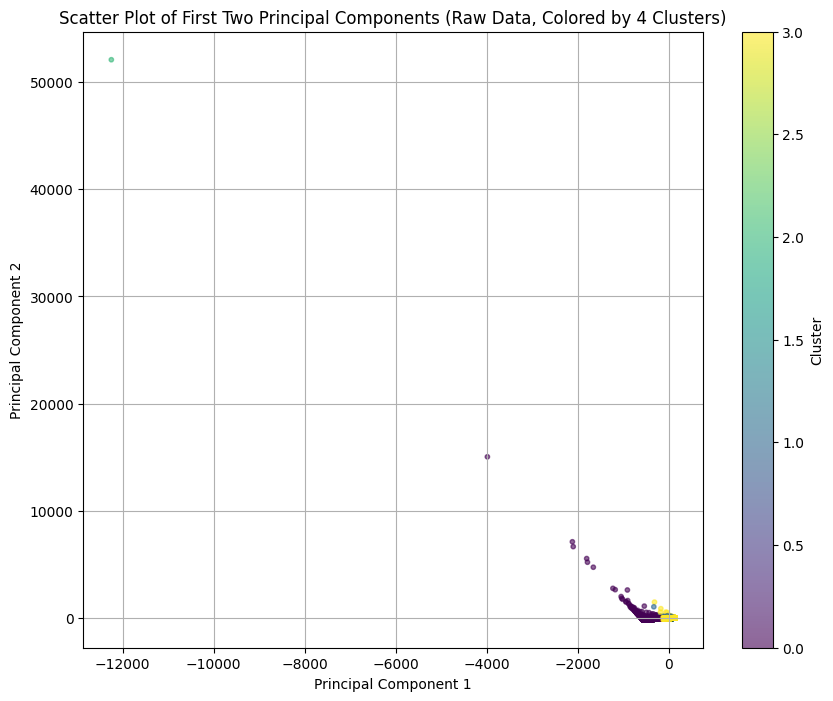

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure numerical_df1 is available from the previous step (clustering on raw data)
if 'numerical_df1' not in locals():
    print("Error: numerical_df1 dataframe not found. Please run the K-Means on raw data step first.")
else:
    # Define the number of clusters (using the optimal_k determined previously)
    optimal_k = 4 # Based on the previous K-Means on raw data cell

    # Apply K-Means Clustering to the raw numerical data
    kmeans_raw = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
    kmeans_raw.fit(numerical_df1)

    # Get the cluster labels
    cluster_labels_raw = kmeans_raw.labels_

    # Reduce dimensionality to 2 components using PCA for visualization
    pca_raw = PCA(n_components=10)
    pca_components_raw = pca_raw.fit_transform(numerical_df1)

    # Create a scatter plot of the first two principal components, colored by cluster
    plt.figure(figsize=(10, 8))

    scatter = plt.scatter(pca_components_raw[:, 0], pca_components_raw[:, 1],
                          c=cluster_labels_raw, cmap='viridis', s=10, alpha=0.6)

    plt.title(f'Scatter Plot of First Two Principal Components (Raw Data, Colored by {optimal_k} Clusters)')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.colorbar(scatter, label='Cluster') # Add a color bar for legend
    plt.grid(True)
    plt.show()